# 04. Huấn Luyện Histogram Gradient Boosting (`nhanes_gbdt.joblib`)
Mô hình Machine Learning chủ lực của `PredictionAgent` (**HistGradientBoostingClassifier** xử lý trực tiếp nhánh rẽ `NaN` mà không cần gán trung vị). Artifact xuất ra `/notebook/model/nhanes_gbdt.joblib`.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebook" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split

from src.models.datasets import DATASETS, load_dataframe, mask_augment
from src.models.tabular_ml import GradientBoostingRisk, risk_report
from src.schemas.patient_profile import PatientProfile
from src.storage.db import engine

spec = DATASETS["nhanes"]
df = load_dataframe(spec, engine)
X, y = df[spec.features].astype(float), df[spec.label].astype(int)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
X_tr_aug, y_tr_aug = mask_augment(X_tr, y_tr, spec, p=0.4, seed=42)
X_te_masked = mask_augment(X_te, y_te, spec, p=0.4, seed=99)[0].iloc[len(X_te):]

gbdt = GradientBoostingRisk.train(spec, X_tr_aug, y_tr_aug)
p_full = gbdt.predict_proba(X_te)
p_mask = gbdt.predict_proba(X_te_masked)
gbdt.metrics = {
    "roc_auc": round(float(roc_auc_score(y_te, p_full)), 4),
    "pr_auc": round(float(average_precision_score(y_te, p_full)), 4),
    "brier": round(float(brier_score_loss(y_te, p_full)), 4),
    "masked_roc_auc": round(float(roc_auc_score(y_te, p_mask)), 4),
}
gbdt.save()
print("Đã lưu artifact:", gbdt.path(spec).relative_to(ROOT))
print("Metrics:", gbdt.metrics)

Đã lưu artifact: notebook/model/nhanes_gbdt.joblib
Metrics: {'roc_auc': 0.8167, 'pr_auc': 0.5241, 'brier': 0.1241, 'masked_roc_auc': 0.7937}


Xác suất nguy cơ ca bệnh mẫu: 0.6343 | Nguy cơ tương đối (RR): 3.21


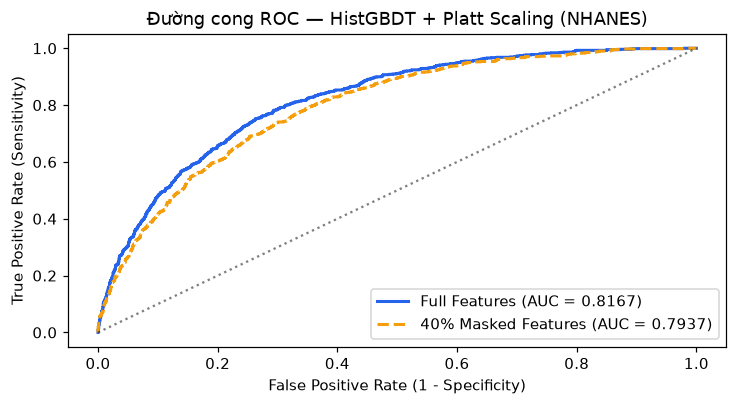

Empty DataFrame
Columns: []
Index: []

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import roc_curve

fpr_f, tpr_f, _ = roc_curve(y_te, p_full)
fpr_m, tpr_m, _ = roc_curve(y_te, p_mask)

fig, ax = plt.subplots(figsize=(6.8, 3.8))
ax.plot(fpr_f, tpr_f, label=f"Full Features (AUC = {gbdt.metrics['roc_auc']:.4f})", lw=2, color="#2563eb")
ax.plot(fpr_m, tpr_m, label=f"40% Masked Features (AUC = {gbdt.metrics['masked_roc_auc']:.4f})", lw=2, ls="--", color="#f59e0b")
ax.plot([0, 1], [0, 1], "k:", alpha=0.5)
ax.set_xlabel("False Positive Rate (1 - Specificity)")
ax.set_ylabel("True Positive Rate (Sensitivity)")
ax.set_title("Đường cong ROC — HistGBDT + Platt Scaling (NHANES)")
ax.legend(loc="lower right")
plt.tight_layout()

profile = PatientProfile(age=56, gender="male", bmi=26.8, systolic_bp=142, diastolic_bp=88, fasting_glucose=131, hba1c=6.8)
rep = risk_report(gbdt, profile)
print("Xác suất nguy cơ ca bệnh mẫu:", rep["risk_probability"], "| Nguy cơ tương đối (RR):", rep["relative_risk"])
pd.DataFrame(rep["top_risk_factors"])
